<a href="https://colab.research.google.com/github/Shekhar94544513/NIC-Training/blob/main/NICLabExercises_Shekhar_Pratap_singh.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# GOT-A Practical Lab Exercises
**Program:** Government Officer Training – Advanced in Artificial Intelligence (GOT-A)  
  
**Notebook:** Exercises 1–5

This notebook follows the five exercises in the supplied NIELIT practical-assessment document. Run the cells from top to bottom.

## Before you start
- Recommended environment: Jupyter Notebook / Google Colab.
- Exercise 5 launches a Gradio web interface. In Colab, use the public share link generated by Gradio.
- Files such as the Excel report, blended images and word-cloud image are saved in the current working directory.

## 0. Install and import required libraries

In [1]:
%pip install -q pandas numpy matplotlib openpyxl opencv-python scikit-image wordcloud gradio

In [2]:
import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image as IPyImage, Markdown

warnings.filterwarnings("ignore")
OUTPUT_DIR = "GOTA_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Output folder:", os.path.abspath(OUTPUT_DIR))

Output folder: /content/GOTA_outputs


# Exercise 1: Exploratory Data Analysis & Automated Reporting with Pandas

**Objective:** Generate a DataFrame with `f1`–`f4`, plot `f2` against `f3`, calculate row-wise mean as `f5`, and export all five columns to Excel.

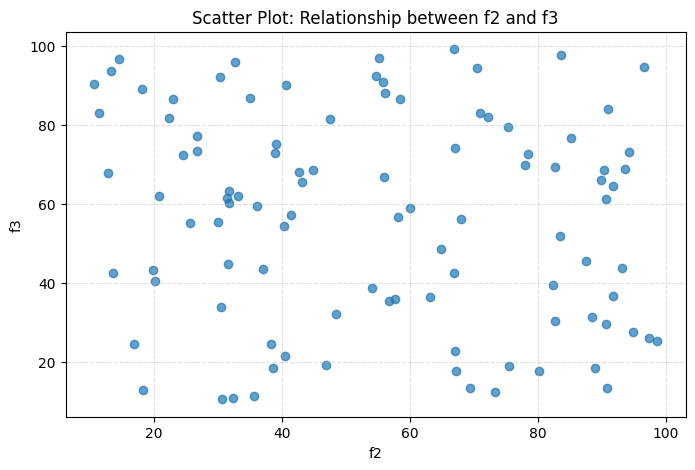

,f1,f2,f3,f4,f5
0,43.708611,12.828627,67.782848,14.651355,34.742860
1,95.564288,67.276937,17.572597,57.821917,59.558935
2,75.879455,38.292038,24.546584,58.657161,49.343810
3,63.879264,55.771362,90.869877,67.368691,69.472298
4,24.041678,91.680983,64.578615,75.348220,63.912374



DataFrame shape: (100, 5)

Descriptive statistics:


,f1,f2,f3,f4,f5
count,100.000000,100.000000,100.000000,100.000000,100.000000
mean,52.316267,54.804855,56.584120,54.203405,54.477162
std,26.774047,26.380013,26.408362,26.410700,10.859099
min,10.496991,10.625692,10.455543,11.295414,25.088682
25%,27.388068,31.780407,34.919188,32.465343,48.826324
50%,51.772821,55.506237,60.629944,55.874647,54.202416
75%,75.718281,78.956524,77.713025,76.219976,61.634061
max,98.819824,98.708541,99.104847,99.145463,79.871018


Excel file saved: /content/GOTA_outputs/Exercise1_Data_Report.xlsx


In [3]:
# Generate reproducible random numerical data
np.random.seed(42)
n_rows = 100

df = pd.DataFrame({
    "f1": np.random.uniform(10, 100, n_rows),
    "f2": np.random.uniform(10, 100, n_rows),
    "f3": np.random.uniform(10, 100, n_rows),
    "f4": np.random.uniform(10, 100, n_rows)
})

# Scatter plot: f2 versus f3
plt.figure(figsize=(8, 5))
plt.scatter(df["f2"], df["f3"], alpha=0.7)
plt.xlabel("f2")
plt.ylabel("f3")
plt.title("Scatter Plot: Relationship between f2 and f3")
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()

# Row-wise arithmetic mean
df["f5"] = df[["f1", "f2", "f3", "f4"]].mean(axis=1)

display(df.head())
print("\nDataFrame shape:", df.shape)
print("\nDescriptive statistics:")
display(df.describe())

# Export all five columns to Excel
excel_path = os.path.join(OUTPUT_DIR, "Exercise1_Data_Report.xlsx")
df.to_excel(excel_path, index=False)
print("Excel file saved:", os.path.abspath(excel_path))

# Exercise 2: Computer Vision — Image Blending Using OpenCV

Two sample images are loaded from `scikit-image`, converted from RGB to OpenCV's BGR format, resized to the same dimensions, blended with `cv2.addWeighted`, displayed and saved. If the sample-image library is unavailable, install it using the installation cell above.

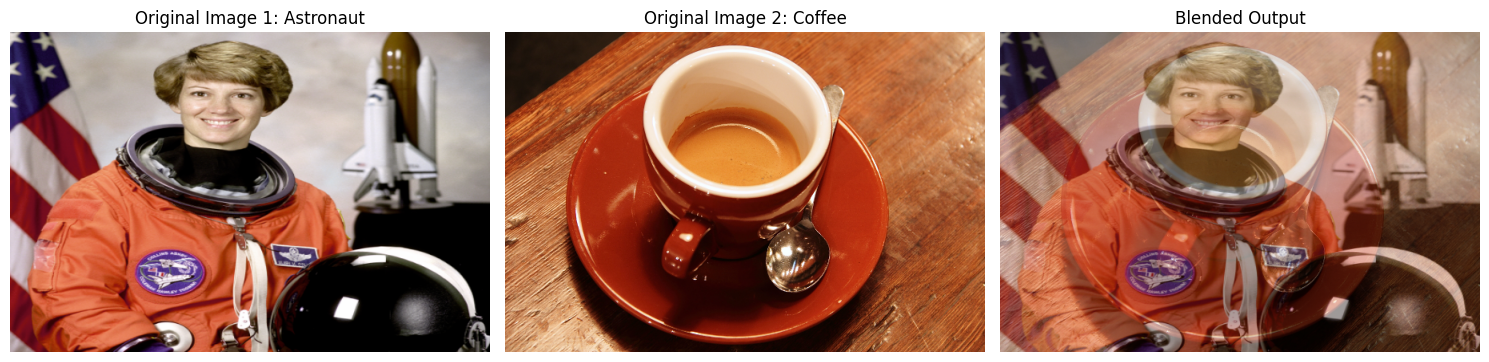

Saved images:
/content/GOTA_outputs/Exercise2_Image1_Astronaut.jpg
/content/GOTA_outputs/Exercise2_Image2_Coffee.jpg
/content/GOTA_outputs/Exercise2_Blended_Image.jpg


In [4]:
import cv2
from skimage import data

# Obtain two sample images (RGB)
image1_rgb = data.astronaut()
image2_rgb = data.coffee()

# Convert RGB to BGR for OpenCV
image1 = cv2.cvtColor(image1_rgb, cv2.COLOR_RGB2BGR)
image2 = cv2.cvtColor(image2_rgb, cv2.COLOR_RGB2BGR)

# Resize both images to identical dimensions
target_width, target_height = 600, 400
image1 = cv2.resize(image1, (target_width, target_height), interpolation=cv2.INTER_AREA)
image2 = cv2.resize(image2, (target_width, target_height), interpolation=cv2.INTER_AREA)

# Weighted blending: 60% image 1 + 40% image 2
blended = cv2.addWeighted(image1, 0.6, image2, 0.4, 0)

# Save all three images
img1_path = os.path.join(OUTPUT_DIR, "Exercise2_Image1_Astronaut.jpg")
img2_path = os.path.join(OUTPUT_DIR, "Exercise2_Image2_Coffee.jpg")
blend_path = os.path.join(OUTPUT_DIR, "Exercise2_Blended_Image.jpg")

cv2.imwrite(img1_path, image1)
cv2.imwrite(img2_path, image2)
cv2.imwrite(blend_path, blended)

# OpenCV uses BGR; convert to RGB for Matplotlib display
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, img, title in zip(
    axes,
    [image1, image2, blended],
    ["Original Image 1: Astronaut", "Original Image 2: Coffee", "Blended Output"]
):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

print("Saved images:")
for path in [img1_path, img2_path, blend_path]:
    print(os.path.abspath(path))

# Exercise 3: Generative AI — Prompt Engineering for Video Synthesis

The assessment asks for the selected video-generation tool, exact prompt, and camera/transition instructions to be documented in **one Markdown cell**.

**Selected tool:** Google Veo  
**Target duration:** 3 seconds

### Exact prompt (single Markdown cell)

Create a cinematic close-up video of a freshly brewed espresso coffee served in a beautiful reddish-brown ceramic cup with a matching saucer on a rustic wooden table. The camera slowly zooms toward the coffee, highlighting its rich golden-brown crema, smooth texture, and warm colour. Soft natural lighting reflects gently on the ceramic cup and silver spoon. Maintain the original composition and realistic details. Use a slow, smooth camera movement with a subtle cinematic effect. No additional objects, no text, no logos, and no watermark. Duration: 3 seconds, 16:9 landscape, ultra-realistic quality.

**Camera instructions:** subtle slow push-in; no camera shake; maintain centered framing.   
**Output:** 3-second, 16:9 landscape video.  


#Exercise 4: E-Commerce Text & Quantitative Analytics
This solution follows the NIELIT GOT-A practical assignment. It uses the Flipkart Product Customer Reviews dataset from Kaggle and performs all three required tasks:
1. Load and clean the dataset.
2. Calculate mean rating and mean price for each product and store the result in items.
3. Generate and display a Word Cloud using the Summary column.

100%|██████████| 3.79M/3.79M [00:00<00:00, 134MB/s]

Extracting files...
Dataset downloaded successfully!
Dataset location: /root/.cache/kagglehub/datasets/niraliivaghani/flipkart-product-customer-reviews-dataset/versions/1
Selected CSV file: /root/.cache/kagglehub/datasets/niraliivaghani/flipkart-product-customer-reviews-dataset/versions/1/Dataset-SA.csv



Dataset Loaded Successfully!
Dataset Shape: (205052, 6)

First Five Records:


,product_name,product_price,Rate,Review,Summary,Sentiment
0,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,super!,great cooler excellent air flow and for this p...,positive
1,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,awesome,best budget 2 fit cooler nice cooling,positive
2,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,the quality is good but the power of air is de...,positive
3,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,1,useless product,very bad product its a only a fan,negative
4,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,ok ok product,neutral



Column Names:
['product_name', 'product_price', 'Rate', 'Review', 'Summary', 'Sentiment']

Data Cleaning Completed!
Cleaned Dataset Shape: (205051, 6)


,product_name,product_price,Rate,Review,Summary,Sentiment
0,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5.0,super!,great cooler excellent air flow and for this p...,positive
1,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5.0,awesome,best budget 2 fit cooler nice cooling,positive
2,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3.0,fair,the quality is good but the power of air is de...,positive
3,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,1.0,useless product,very bad product its a only a fan,negative
4,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3.0,fair,ok ok product,neutral



Product-wise Mean Rating and Mean Price:


,product_name,Mean_Rating,Mean_Price
0,1170BLBR Unique New Day Date Analog Watch F...,3.99,299.0
1,288SDTL TIMEWEAR Silver Pink Dial Stainless St...,4.41,339.0
2,38024PP25 Minimalists Analog Watch For Men,4.89,850.0
3,3D METRO SUPER STORE JUICERGduumy 1 Juicer1 Ha...,3.67,417.0
4,3D METRO SUPER STORE METROMIXER Pro 0 Juicer 1...,4.75,199.0
5,77085PP03 Volt Analog Watch For Men,4.71,699.0
6,7SEVEN Airtel DTH Remote Airtel Xstream Remote...,4.69,219.0
7,"ADONYX Combo of Knee,Palm, Elbow & Ankle Support",3.80,199.0
8,ADZOY Metal Lazy Stand Bracket for Neck Rest o...,3.52,284.0
9,AGAMI Green 2 Layer Lucky Bamboo plant with Bi...,4.46,279.0



Total Unique Products: 958


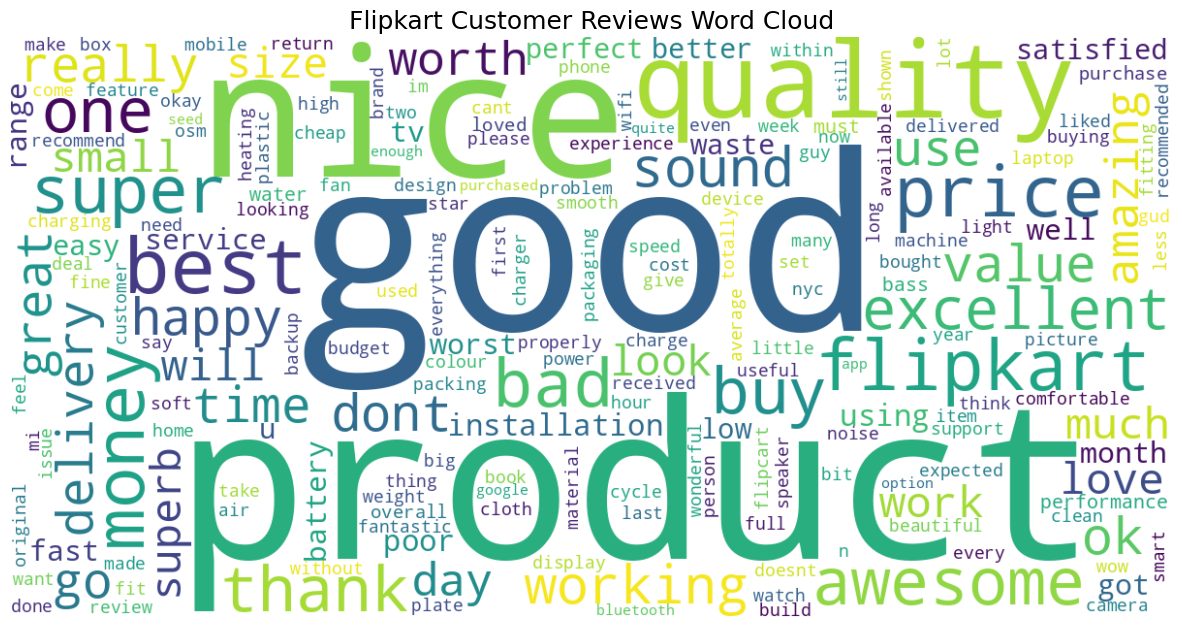

Word Cloud Image Saved Successfully!
Excel File Saved Successfully!

========== FINAL RESULTS ==========
Original Dataset Records: 205052
Cleaned Dataset Records: 205051
Total Products: 958

Final Product Summary:


,product_name,Mean_Rating,Mean_Price
0,1170BLBR Unique New Day Date Analog Watch F...,3.99,299.0
1,288SDTL TIMEWEAR Silver Pink Dial Stainless St...,4.41,339.0
2,38024PP25 Minimalists Analog Watch For Men,4.89,850.0
3,3D METRO SUPER STORE JUICERGduumy 1 Juicer1 Ha...,3.67,417.0
4,3D METRO SUPER STORE METROMIXER Pro 0 Juicer 1...,4.75,199.0
...,...,...,...
953,tHemiStO Beginners 8 in 1 Soldering iron Kit 2...,4.24,232.0
954,the indian casa Cricket Net 10x20 Feet Nylon C...,3.92,340.0
955,thos 5 Layer Simple BookshelfMultipurpose Rack...,3.38,785.0
956,thos 5 Layer Simple BookshelfMultipurpose Rack...,3.41,799.0



Generated Files:
1. Flipkart_Product_Summary.xlsx
2. Flipkart_WordCloud.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Exercise 4 Completed Successfully!


In [10]:

# ============================================================
# EXERCISE 4: E-COMMERCE TEXT & QUANTITATIVE ANALYTICS
# NIELIT GOT-A Practical Assessment
# ============================================================

# STEP 1: Install Required Libraries

!pip install -q kagglehub pandas numpy matplotlib wordcloud openpyxl


# STEP 2: Import Libraries

import os
import glob
import re
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from wordcloud import WordCloud, STOPWORDS
from IPython.display import display


# STEP 3: Download Dataset Directly from Kaggle

print("Downloading Flipkart Customer Reviews Dataset...")

dataset_path = kagglehub.dataset_download(
    "niraliivaghani/flipkart-product-customer-reviews-dataset"
)

print("Dataset downloaded successfully!")
print("Dataset location:", dataset_path)


# STEP 4: Find CSV File Automatically

csv_files = glob.glob(
    os.path.join(dataset_path, "**", "*.csv"),
    recursive=True
)

if not csv_files:
    raise FileNotFoundError("No CSV file found in downloaded dataset.")

# Prefer Dataset-SA.csv if available
preferred_files = [
    f for f in csv_files
    if os.path.basename(f).lower() == "dataset-sa.csv"
]

csv_file = preferred_files[0] if preferred_files else csv_files[0]

print("Selected CSV file:", csv_file)


# STEP 5: Load Dataset into Pandas DataFrame

df = pd.read_csv(csv_file)

print("\nDataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

print("\nFirst Five Records:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())


# STEP 6: Data Cleaning

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Check required columns
required_columns = [
    'product_name',
    'product_price',
    'Rate',
    'Summary'
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns missing: {missing_columns}"
    )

# Function to convert price and rating into numeric values
def clean_numeric(series):

    series = series.astype(str)

    series = series.str.replace(
        ',', '', regex=False
    )

    series = series.str.extract(
        r'(-?\d+\.?\d*)'
    )[0]

    return pd.to_numeric(series, errors='coerce')


# Clean Rating
df['Rate'] = clean_numeric(df['Rate'])

# Clean Price
df['product_price'] = clean_numeric(
    df['product_price']
)

# Clean Product Name
df['product_name'] = (
    df['product_name']
    .astype('string')
    .str.strip()
)

# Remove invalid and missing records
df.dropna(
    subset=[
        'product_name',
        'Rate',
        'product_price'
    ],
    inplace=True
)

# Keep valid ratings between 1 and 5
df = df[
    (df['Rate'] >= 1) &
    (df['Rate'] <= 5) &
    (df['product_price'] >= 0) &
    (df['product_name'] != '')
].copy()

print("\nData Cleaning Completed!")

print("Cleaned Dataset Shape:", df.shape)

display(df.head())


# STEP 7: Group Data by Product Name
# Calculate Mean Rating and Mean Price

items = df.groupby('product_name').agg(

    Mean_Rating=('Rate', 'mean'),

    Mean_Price=('product_price', 'mean')

).reset_index()

# Round mean values
items['Mean_Rating'] = items['Mean_Rating'].round(2)

items['Mean_Price'] = items['Mean_Price'].round(2)

print("\nProduct-wise Mean Rating and Mean Price:")

display(items.head(10))

print("\nTotal Unique Products:", len(items))


# STEP 8: Generate Word Cloud Using Summary Column

# Remove missing Summary values
summary_text = df['Summary'].dropna().astype(str)

# Combine all customer feedback
text = " ".join(summary_text)

# Remove empty text
text = re.sub(r'\s+', ' ', text).strip()

if not text:
    raise ValueError("No valid text found in Summary column.")

# Define Stopwords
stopwords = set(STOPWORDS)

# Generate Word Cloud
wordcloud = WordCloud(

    width=1200,

    height=600,

    background_color='white',

    stopwords=stopwords,

    max_words=200,

    collocations=False,

    colormap='viridis'

).generate(text)


# Display Word Cloud
plt.figure(figsize=(15, 8))

plt.imshow(
    wordcloud,
    interpolation='bilinear'
)

plt.axis('off')

plt.title(
    'Flipkart Customer Reviews Word Cloud',
    fontsize=18
)

plt.show()


# STEP 9: Save Word Cloud Image

wordcloud.to_file(
    'Flipkart_WordCloud.png'
)

print("Word Cloud Image Saved Successfully!")


# STEP 10: Export Product Summary to Excel

excel_file = 'Flipkart_Product_Summary.xlsx'

items.to_excel(
    excel_file,
    index=False
)

print("Excel File Saved Successfully!")


# STEP 11: Display Final Results

print("\n========== FINAL RESULTS ==========")

print("Original Dataset Records:", len(pd.read_csv(csv_file)))

print("Cleaned Dataset Records:", len(df))

print("Total Products:", len(items))

print("\nFinal Product Summary:")

display(items)

print("\nGenerated Files:")

print("1. Flipkart_Product_Summary.xlsx")

print("2. Flipkart_WordCloud.png")


# STEP 12: Download Generated Files in Google Colab

from google.colab import files

files.download('Flipkart_Product_Summary.xlsx')

files.download('Flipkart_WordCloud.png')

print("\nExercise 4 Completed Successfully!")


# Exercise 5: Interactive AI Prototyping with Gradio

This creates a browser-based conversational demonstration using `gr.ChatInterface`. It is a lightweight rule-based chatbot (not a connected large language model), so it runs without an API key. The two example prompts can be clicked in the interface. In Colab, set `share=True` to obtain a public temporary link.

In [11]:
import gradio as gr

def officer_training_bot(message, history):
    text = message.lower().strip()

    if any(word in text for word in ["hello", "hi", "namaste", "good morning"]):
        return "Hello! Welcome to the GOT-A AI practical demonstration. How can I help you?"
    elif "pandas" in text or "dataframe" in text:
        return "Pandas is a Python library used to load, clean, analyse and summarise tabular data using DataFrames."
    elif "image" in text or "opencv" in text or "blend" in text:
        return "OpenCV is a computer-vision library. The addWeighted() function blends two same-sized images using specified weights."
    elif "word cloud" in text or "review" in text:
        return "A Word Cloud visualises frequent words in text. Before generating it, clean missing values and remove common stop words."
    elif "gradio" in text or "chatbot" in text:
        return "Gradio provides a simple way to create a web interface for a Python function or conversational application."
    elif "ai" in text or "artificial intelligence" in text:
        return "Artificial Intelligence enables computer systems to perform tasks such as language processing, prediction, image analysis and decision support."
    else:
        return ("Thank you for your question. This demonstration chatbot supports basic topics related to "
                "AI, Pandas, OpenCV, Word Clouds and Gradio. Try one of the example prompts.")

demo = gr.ChatInterface(
    fn=officer_training_bot,
    title="GOT-A AI Assistant",
    description="Welcome to the Government Officer Training – Advanced in AI demonstration. Ask a question about Python data analysis, computer vision, text analytics or AI.",
    examples=[
        "What is Pandas and a DataFrame?",
        "How does OpenCV image blending work?"
    ],
    chatbot=gr.Chatbot(height=400),
    textbox=gr.Textbox(placeholder="Type your question here...", container=False, scale=7)
)

# Launch the interface. In Google Colab, share=True provides a temporary public URL.
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://0514d9614969c3a5b5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
